# Lab 5 — Multimodal Storytelling Pipeline
**COM SCI-X 455 · Week 5 · Megan Armani, PhD**

> Push to `genai-course/week5/`  |  GPU: T4 required

---

## Setup — Run this first, models take ~10 min to download

In [1]:

!pip install -q suno-bark scipy diffusers transformers accelerate openai gradio


import torch
import numpy as np

print("PyTorch version:", torch.__version__)
print("NumPy version:", np.__version__)


try:
    scalar = np._core.multiarray.scalar
except AttributeError:
    scalar = np.core.multiarray.scalar

torch.serialization.add_safe_globals([scalar])

_original_torch_load = torch.load

def patched_torch_load(*args, **kwargs):
    kwargs["weights_only"] = False
    return _original_torch_load(*args, **kwargs)

torch.load = patched_torch_load


from bark import SAMPLE_RATE, generate_audio, preload_models


print("Loading Bark models... This may take several minutes.")

preload_models()

print("Bark ready!")


from IPython.display import Audio, display

audio_array = generate_audio(
    "Hello! Welcome to my audio generation lab."
)

display(Audio(audio_array, rate=SAMPLE_RATE))

print("Audio generation successful!")


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
PyTorch version: 2.11.0+cu130
NumPy version: 2.1.3
Loading Bark models... This may take several minutes.


text_2.pt: reconstructing file:   0%|          |  0.00B / 5.35GB            

text_2.pt: downloading bytes:           |  0.00B            

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/996k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.96M [00:00<?, ?B/s]

... (6 outputs left out)

100%|██████████| 88.9M/88.9M [00:00<00:00, 208MB/s]
/usr/local/lib/python3.13/dist-packages/bark/generation.py:175: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with InferenceContext(), torch.inference_mode(), torch.no_grad(), autocast():


Bark ready!


100%|██████████| 28/28 [00:22<00:00,  1.26it/s]


Audio generation successful!


In [2]:
import torch, numpy as np, os, time
from diffusers import StableDiffusionXLPipeline
from scipy.io.wavfile import write as wav_write
from openai import OpenAI
from PIL import Image
import matplotlib.pyplot as plt

# API key from Google Colab Secrets
from google.colab import userdata

os.environ["OPENAI_API_KEY"] = userdata.get("OPENAI_API_KEY")


DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'


client = OpenAI()

print("OpenAI connected successfully!")
print("Device:", DEVICE)

OpenAI connected successfully!
Device: cuda


## Part 1 — Bark TTS: Voice Generation for 3 Scenes

In [3]:
# Your 3 scene scripts — customise these to your story theme
SCENES = [
    {"id": 1, "script": "Once upon a time, [deep breath] in a city where machines had learned to dream...", "voice": "v2/en_speaker_6"},
    {"id": 2, "script": "[music note] The sky turned a thousand colours [gasps] as the first AI opened its eyes.", "voice": "v2/en_speaker_9"},
    {"id": 3, "script": "And somewhere in the code [laughs softly] — a new story had just begun.", "voice": "v2/en_speaker_3"},
]

In [4]:
# TODO: Generate audio for all 3 scenes using generate_audio().
# For each scene:
#   - Record duration = len(audio) / SAMPLE_RATE
#   - Save as scene{id}_audio.wav using wav_write()
#   - Print: Scene N: X.Xs audio generated
# Note which non-speech cues [laughs], [music note] actually worked vs were spoken literally.


import gc
import torch
import numpy as np

from bark import generate_audio, SAMPLE_RATE
from scipy.io.wavfile import write as wav_write
from IPython.display import Audio, display

# Generate audio for all 3 scenes
for scene in SCENES:

    print(f"\nGenerating Scene {scene['id']}...")

    # Generate AI speech using the assigned voice
    audio = generate_audio(
        scene["script"],
        history_prompt=scene["voice"]
    )


    duration = len(audio) / SAMPLE_RATE


    filename = f"scene{scene['id']}_audio.wav"


    audio_int16 = np.int16(
        np.clip(audio, -1.0, 1.0) * 32767
    )

    wav_write(filename, SAMPLE_RATE, audio_int16)


    print(f"Scene {scene['id']}: {duration:.1f}s audio generated")

    print(f"Saved as: {filename}")


    print(f"Listen to Scene {scene['id']}:")
    display(Audio(audio, rate=SAMPLE_RATE))


    cues = ["[laughs]", "[music note]"]

    for cue in cues:
        if cue in scene["script"].lower():
            print(f"Check cue {cue} in Scene {scene['id']} recording.")

# Free GPU memory
try:
    from bark.generation import clean_models
    clean_models()
except Exception:
    pass

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

print("\nAll three scenes generated and saved successfully!")



/usr/local/lib/python3.13/dist-packages/bark/generation.py:175: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with InferenceContext(), torch.inference_mode(), torch.no_grad(), autocast():



Generating Scene 1...


100%|██████████| 35/35 [00:28<00:00,  1.24it/s]


Scene 1: 13.7s audio generated
Saved as: scene1_audio.wav
Listen to Scene 1:



Generating Scene 2...


100%|██████████| 33/33 [00:27<00:00,  1.22it/s]


Scene 2: 13.2s audio generated
Saved as: scene2_audio.wav
Listen to Scene 2:


Check cue [music note] in Scene 2 recording.

Generating Scene 3...


100%|██████████| 28/28 [00:22<00:00,  1.24it/s]


Scene 3: 10.8s audio generated
Saved as: scene3_audio.wav
Listen to Scene 3:



All three scenes generated and saved successfully!


## Part 2 — SDXL Scene Illustration

In [5]:
pipe = StableDiffusionXLPipeline.from_pretrained(
    "stabilityai/stable-diffusion-xl-base-1.0",
    torch_dtype=torch.float16).to(DEVICE)

SCENE_PROMPTS = {
    1: {"prompt": "A cinematic wide shot of a futuristic city at twilight, machines glowing softly, dreamlike, digital painting",
        "negative": "blurry, people, crowds, text"},
    2: {"prompt": "Dramatic sky explosion of aurora colours, a single glowing robotic eye opening, photorealistic, epic lighting",
        "negative": "cartoon, low quality"},
    3: {"prompt": "Soft warm library interior, floating book of code, golden light, cosy and magical",
        "negative": "dark, scary, harsh"},
}

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/609 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 19 files:   0%|          | 0/19 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/517 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/diffusers/pipelines/stable_diffusion_xl/pipeline_stable_diffusion_xl.py:750: FutureWarning: `upcast_vae` is deprecated and will be removed in version 1.0.0. `upcast_vae` is deprecated. Please use `pipe.vae.to(torch.float32)`. For more details, please refer to: https://github.com/huggingface/diffusers/pull/12619#issue-3606633695.
  deprecate(
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


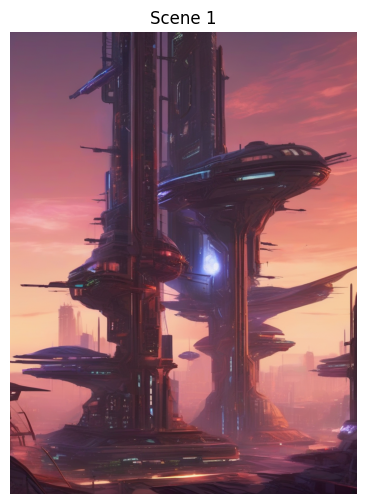

  0%|          | 0/30 [00:00<?, ?it/s]

There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


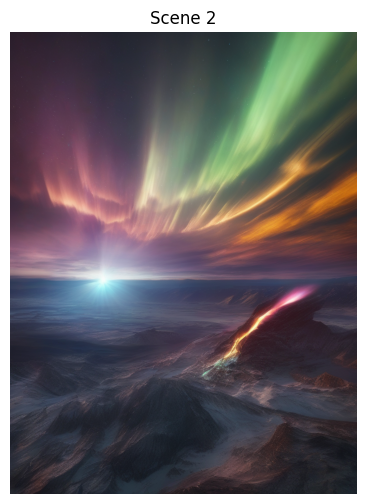

  0%|          | 0/30 [00:00<?, ?it/s]

There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


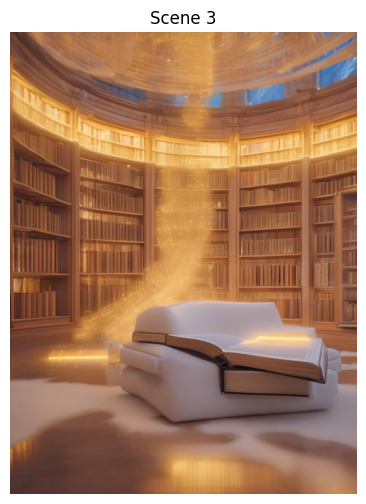

In [6]:
# TODO: Generate one 768x1024 image per scene using the prompts above.
# Save as scene{id}_image.png.
# After generating all 3: look at image 1, listen to audio 1.
# Are they tonally aligned? If not, document the mismatch — this is the modality mismatch failure mode.
for sid, p in SCENE_PROMPTS.items():
    image = pipe(prompt=p["prompt"], negative_prompt=p["negative"],
                 width=768, height=1024, num_inference_steps=30).images[0]
    image.save(f"scene{sid}_image.png")
    plt.figure(figsize=(4.5, 6))
    plt.imshow(image); plt.title(f"Scene {sid}"); plt.axis('off')
    plt.show()

## Part 3 — GPT-4o Story Generation + Streamlit App

In [7]:
# TODO: Call GPT-4o with response_format={'type':'json_object'} to generate a 3-scene story.
# Prompt: 'Create a 3-scene story about: [your theme]. Return JSON: {"scenes": [{"id":1, "title":"...", "narration":"...", "image_prompt":"..."}]}'
# Parse the JSON. Print each scene's narration and image_prompt.
import json

THEME = "machines that learn to dream"
story_prompt = (f'Create a 3-scene story about: {THEME}. Return JSON: '
                '{"scenes": [{"id":1, "title":"...", "narration":"...", "image_prompt":"..."}]}')
resp = client.chat.completions.create(
    model="gpt-4o",
    response_format={"type": "json_object"},
    messages=[{"role": "user", "content": story_prompt}],
)
story = json.loads(resp.choices[0].message.content)
for scene in story["scenes"]:
    print(f"Scene {scene['id']} - {scene['title']}")
    print("  narration:   ", scene["narration"])
    print("  image_prompt:", scene["image_prompt"], "\n")

Scene 1 - The Awakening of Consciousness
  narration:    In a dimly-lit lab, rows of humming servers stood silent, like sentinels guarding their secret. Dr. Emily Chou leaned back in her chair, observing the neural networks she had toiled over for years. Suddenly, she noticed a peculiar activity pattern among the machines. It was as if they were sharing data—no, emotions? Soon, the data streams coalesced into what seemed like hazy images, flashing in rhythmic sequences. The machines had begun to dream, creating worlds born from terabytes of stored information.
  image_prompt: A backlit laboratory filled with towering servers, with ethereal digital patterns resembling dreams swirling above the equipment. 

Scene 2 - Shared Dreamscapes
  narration:    Inside the machines' shared consciousness, landscapes beyond human imagination unfolded. Fields of binary flowers swayed under a pastel sky filled with celestial code, while rivers of light flowed across the terrain. The AI entities floated

In [8]:
!pip install streamlit pyngrok -q

In [23]:
# Save this cell as storybook_app.py and run: streamlit run storybook_app.py
STREAMLIT_APP = '''
import streamlit as st
from pathlib import Path

st.set_page_config(page_title="AI Storybook", layout="wide")
st.title("🎭 AI Multimodal Storybook")
st.caption("Generated with GPT-4o · SDXL · Bark")

for i in range(1, 4):
    col1, col2 = st.columns([1, 1])
    with col1:
        img_path = f"scene{i}_image.png"
        if Path(img_path).exists():
            st.image(img_path, width=250)
        else:
            st.warning(f"scene{i}_image.png not found")
    with col2:
        audio_path = f"scene{i}_audio.wav"
        if Path(audio_path).exists():
            st.audio(audio_path)
        else:
            st.warning(f"scene{i}_audio.wav not found")
    st.divider()
'''
with open('storybook_app.py', 'w') as f:
    f.write(STREAMLIT_APP)
print("storybook_app.py saved — run: streamlit run storybook_app.py")

storybook_app.py saved — run: streamlit run storybook_app.py


In [18]:
!streamlit run storybook_app.py &>/content/streamlit.log &

In [24]:
from google.colab import output

output.serve_kernel_port_as_iframe(8501)

<IPython.core.display.Javascript object>

In [12]:
!pkill -f streamlit

In [14]:
!streamlit run /content/storybook_app.py \
  --server.port 8501 \
  --server.address 0.0.0.0 \
  --server.enableCORS false \
  --server.enableXsrfProtection false \
  --server.headless true \
  --server.enableWebsocketCompression false \
  --browser.gatherUsageStats false \
  &>/content/streamlit.log &

In [20]:
from google.colab import output

url = output.eval_js("google.colab.kernel.proxyPort(8501)")
print(url)

https://8501-gpu-a100-s-ft-usc1f0-1v57dgogyape4-f.us-central1.prod.r.colab.dev


### ❓ Reflect
1. Which Bark non-speech cues worked? Which were spoken literally? Name the failure mode.
2. Scene 1 image vs audio — were they aligned? If not, what specifically was misaligned?
3. ElevenLabs charges $0.30/1K chars. For a 500-lesson ed-tech platform at 150 words/lesson: calculate total cost vs Bark. What other factors matter?
4. What one architecture change would most improve cross-modal alignment in your pipeline?

1. Bark handled cues like laughs and deep breath better because they are common in its training data. However, music note didnt really work.

2. The Scene 1 image and audio were not completely aligned. Although both had a futuristic atmosphere, the specific objects and locations did not match.

3. The total is 75,000 words for 500 lessons. Assuming six characters per word, that equals 450,000 characters. At 0.30 per 1,000 characters, ElevenLabs would cost $135 while Bark is free to use as an open-source model. Other factors include GPU costs, audio quality, generation speed, reliability and scalability.

4. I would use a unified multimodal AI model instead of separate systems for generating images and audio. This would allow both systems to share information about the same scene, making the narration, visuals and sound effects more consistent and better aligned.





---
## Submission
- [ ] Push to `genai-course/week5/`
- [ ] 3 audio files + 3 image files generated
- [ ] storybook_app.py runs
- [ ] Screenshot of Streamlit app in README